Name: Trang Nguyen

ID: 1622316

Oversampling Techniques for Imbalanced Datasets: ***S***ynthetic ***M***inority ***O***versamplimg ***Te***chnique (SMOTE)

Handling imbalanced data in Python involves techniques to address the issue where one class has significantly more instances than the other class. This can lead to biased models that perform poorly on the minority class. https://www.kaggle.com/code/jtengsun/best-techniques-and-metrics-for-imbalanced-dataset/edit
In the last assignment you used *Random Oversampling* to balance the dataset. This assignment you will use [SMOTE](https://www.analyticsvidhya.com/blog/2020/10/overcoming-class-imbalance-using-smote-techniques/) to balance the distribution of classes by increasing the number of samples in the minority class (1). It balances the distribution of classes by increasing the number of samples in the minority class.


# **Description of the dataset**

The dataset contains 14,999 samples, and 9 attributes or features (6 integer, 2 float, and 2 objects), and 'left', the 'Target' variable  (what we want to predict).

The 10 variables are as follows:

1. satisfaction_level: employee satisfaction (0-1).  
2. last_evaluation: evaluated performance by the employer (0-1).
3. number_projects: numbers of projects assigned to an employee
4. average_monthly_hours: ave numbers of hours worked by an employee in a month
5. time_spent_company: employee experience measured as number of years in Co.
6. work_accident: Whether an employee has had a work accident
7. promotion_last_5years: promotion in the last 5 years
8. Departments: Employee's department
9. Salary: Salary level of the employee (low, medium and high).
10.left: 1 = employee left the Co. 0 = did not leave.

In [ ]:
#import modules
import matplotlib.pyplot as plt # for plotting graphs
import seaborn as sns # for plotting graphs
import numpy as np
import pandas as pd
#MODEL
from imblearn.over_sampling import SMOTE # will not use this yet
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

In [ ]:
HRdf=pd.read_csv('/content/HR_Employee_churn.csv')

In this dataset, we have two types of employee, those who stayed and those that left the company. Compare their characteristics by group (the column 'left'). Here, you can find the average of both the groups using groupby() and mean() function.

In [ ]:
HRdf

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


We will encode the categorical features ('Department' and 'salary')

In [ ]:
# Replace 'Department' with the actual column name if there is a typo.
HRdf = pd.get_dummies(HRdf, columns=['Departments'], prefix='Dept', dtype=int)

Building a Prediction Model

Pre-Processing Data

Machine learning algorithms require numerical input data, so you need to represent categorical columns in a numerical column. In order to encode this data, you could map each value to a number. e.g. Salary column's value can be represented as low:0, medium:1, and high:2. This process is known as label encoding, and sklearn conveniently will do this for you using LabelEncoder.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Fit the encoder to the 'Salary' column and transform it
HRdf['Encoded_salary'] = label_encoder.fit_transform(HRdf['salary'])

# Optionally, you can drop the original 'Salary' column
HRdf = HRdf.drop('salary', axis=1)

In [ ]:
HRdf

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.38,0.53,2,157,3,0,1,0,0,0,0,0,0,0,0,1,0,0,1
1,0.80,0.86,5,262,6,0,1,0,0,0,0,0,0,0,0,1,0,0,2
2,0.11,0.88,7,272,4,0,1,0,0,0,0,0,0,0,0,1,0,0,2
3,0.72,0.87,5,223,5,0,1,0,0,0,0,0,0,0,0,1,0,0,1
4,0.37,0.52,2,159,3,0,1,0,0,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14995,0.37,0.48,2,160,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14996,0.37,0.53,2,143,3,0,1,0,0,0,0,0,0,0,0,0,1,0,1
14997,0.11,0.96,6,280,4,0,1,0,0,0,0,0,0,0,0,0,1,0,1


Take a look at the Imbalance datset i.e the 'left' feature

left
0    11428
1     3571
Name: count, dtype: int64


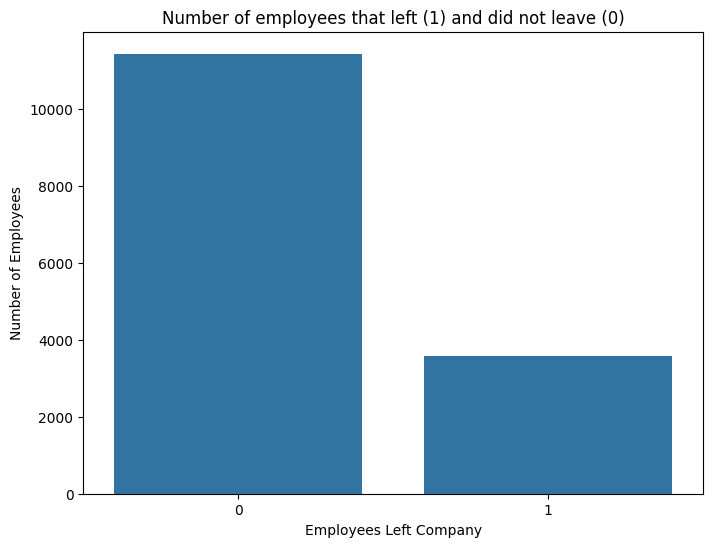

In [ ]:
left_count = HRdf['left'].value_counts()
print(left_count)

plt.figure(figsize=(8, 6))  # Adjust figure size
sns.countplot(x='left', data=HRdf)  # Using countplot with seaborn
plt.title('Number of employees that left (1) and did not leave (0)')
plt.xlabel('Employees Left Company')
plt.ylabel('Number of Employees')
plt.show()

In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
# Assuming 'left' is the target variable and all other columns are features
X = HRdf.drop('left', axis=1)  # Features (all columns except 'left')
y = HRdf['left']  # Target variable ('left' column)


# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # 70% training, 30% test

In [ ]:
X

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,1
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,2
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,2
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,1
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14995,0.37,0.48,2,160,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14996,0.37,0.53,2,143,3,0,0,0,0,0,0,0,0,0,0,1,0,1
14997,0.11,0.96,6,280,4,0,0,0,0,0,0,0,0,0,0,1,0,1


In [ ]:
y

,left
0,1
1,1
2,1
3,1
4,1
...,...
14994,1
14995,1
14996,1
14997,1


Use SMOTE to balance the data

Apply SMOTE to the X-train and y_train to balance the dtatset.  Follow the assignment 7 from here to crete a table to compare the Performance results,

In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTE
# Create a SMOTE object and fit it only to the training dataset (X_train, y_train)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [ ]:
y_train

,left
12602,1
4889,0
1572,1
13375,0
879,1
...,...
5191,0
13418,0
5390,0
860,1


In [ ]:
y_train_smote

,left
0,1
1,0
2,1
3,0
4,1
...,...
15995,1
15996,1
15997,1
15998,1


In [ ]:
X_train_smote

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,Dept_IT,Dept_RandD,Dept_accounting,Dept_hr,Dept_management,Dept_marketing,Dept_product_mng,Dept_sales,Dept_support,Dept_technical,Encoded_salary
0,0.100000,0.840000,7,250,4,0,0,0,0,0,0,0,0,1,0,0,0,1
1,0.570000,0.680000,4,154,3,1,0,0,0,0,0,1,0,0,0,0,0,2
2,0.390000,0.480000,2,154,3,0,0,0,0,0,0,0,0,0,0,0,1,1
3,0.910000,0.680000,4,132,4,0,0,1,0,0,0,0,0,0,0,0,0,2
4,0.820000,0.970000,5,263,5,0,0,0,0,0,0,0,0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,0.094502,0.915498,6,253,4,0,0,0,0,0,0,0,0,0,1,0,0,2
15996,0.808910,0.966073,5,243,5,0,0,0,0,0,0,0,0,0,0,0,1,2
15997,0.410000,0.550000,2,154,3,0,0,0,0,0,0,0,0,0,0,1,0,1
15998,0.383217,0.668560,2,151,3,0,0,0,0,0,0,0,0,0,0,0,1,1


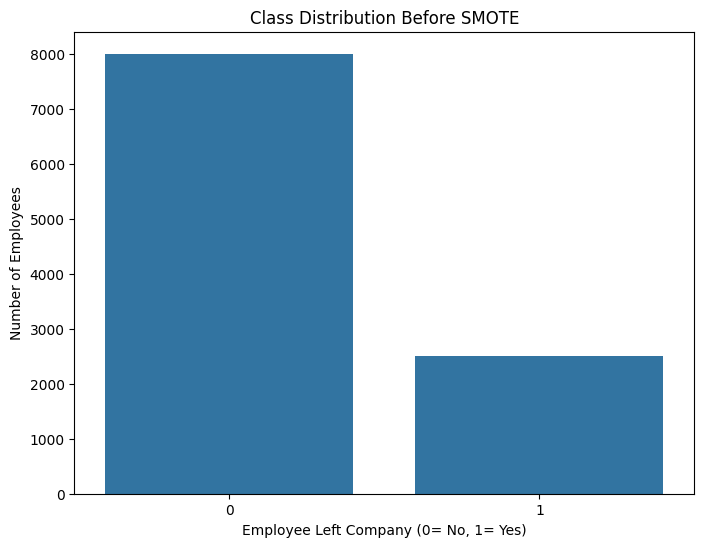

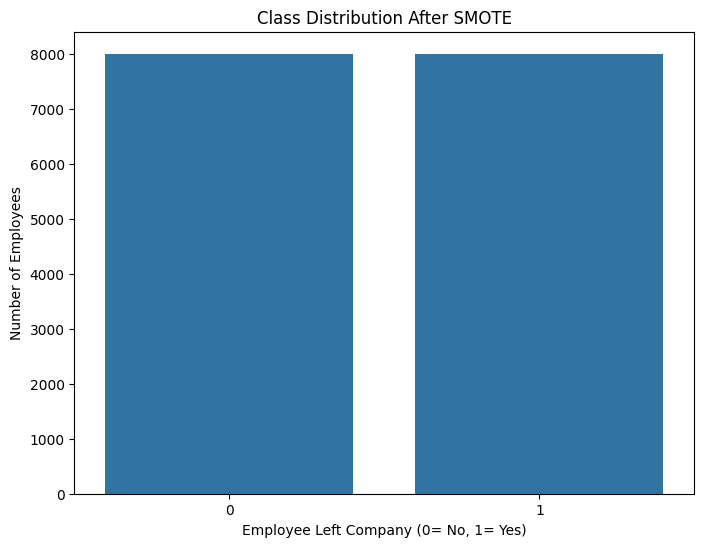

In [ ]:
import matplotlib.pyplot as plt
# Countplot of original dataset
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train)
plt.title('Class Distribution Before SMOTE')
plt.xlabel('Employee Left Company (0= No, 1= Yes)')
plt.ylabel('Number of Employees')
plt.show()


# Countplot of SMOTE-balanced dataset
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train_smote)
plt.title('Class Distribution After SMOTE')
plt.xlabel('Employee Left Company (0= No, 1= Yes)')
plt.ylabel('Number of Employees')
plt.show()


**Model Building**

**There are a number of classification models:**
1.   logistic regression
2.   decision tree
1.   random forest
1.   gradient-boosted tree
2.   multilayer perceptron
2.   one-vs-rest (mainly for multiple class)
1.   Naive Bayes
1.   Support Vector Machine (SVM)





To use the various Classifier.
First, import the Classifier module and create classifier object using Classifier() function.
Then, fit your model on training set using fit() and perform prediction on the test set using predict().

Evaluating Model Performance with the test dataset "y_test" efore and after applyiing SMOTE

**Decision Tree**

In [ ]:
# Use Decision Tree to predict before SMOTE
# Import the Scikit Learn Decision Tree module
from sklearn.tree import DecisionTreeClassifier

# Create an instance of Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)  # You can adjust hyperparameters here

# Train the model using the training sets
dt.fit(X_train, y_train)

# Predict the response for the test dataset
dt_y_pred = dt.predict(X_test)

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Decision Tree Performance Before SMOTE')
print("Accuracy:",metrics.accuracy_score(y_test, dt_y_pred))
# Model Precision
print("Precision:",metrics.precision_score(y_test, dt_y_pred))
# Model Recall
print("Recall:",metrics.recall_score(y_test, dt_y_pred))
# Calculate F1 score
f1 = metrics.f1_score(y_test, dt_y_pred)
print("F1 score:",metrics.f1_score(y_test, dt_y_pred))

Decision Tree Performance Before SMOTE
Accuracy: 0.9762222222222222
Precision: 0.9414455626715462
Recall: 0.9598880597014925
F1 score: 0.9505773672055428


In [ ]:
# Use Decision Tree to predict After SMOTE
# Import the Scikit Learn Decision Tree module
from sklearn.tree import DecisionTreeClassifier

# Create an instance of Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)  # You can adjust hyperparameters here

# Train the model using the training sets
dt.fit(X_train_smote, y_train_smote)

# Predict the response for the test dataset
dt_smote_y_pred = dt.predict(X_test)

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print('Decision Tree Performance After SMOTE')
print("Accuracy:",metrics.accuracy_score(y_test, dt_smote_y_pred))
# Model Precision
print("Precision:",metrics.precision_score(y_test, dt_smote_y_pred))
# Model Recall
print("Recall:",metrics.recall_score(y_test, dt_smote_y_pred))
# Calculate F1 score
f1 = metrics.f1_score(y_test, dt_smote_y_pred)
print("F1 score:",metrics.f1_score(y_test, dt_smote_y_pred))

Decision Tree Performance After SMOTE
Accuracy: 0.9611111111111111
Precision: 0.8869715271786023
Recall: 0.9589552238805971
F1 score: 0.9215598386373823


**Evaluating Model Performance**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools
def plot_confusion_matrix(cm, classes,
                          normalize=True,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True` above.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
print(confusion_matrix(y_test, dt_y_pred, labels=[1,0]))

[[1029   43]
 [  64 3364]]


In [ ]:
# Compute confusion matrix
cnf_matrix_dt = confusion_matrix(y_test, dt_y_pred, labels=[1,0])
np.set_printoptions(precision=2)

Confusion matrix, without normalization
[[1029   43]
 [  64 3364]]


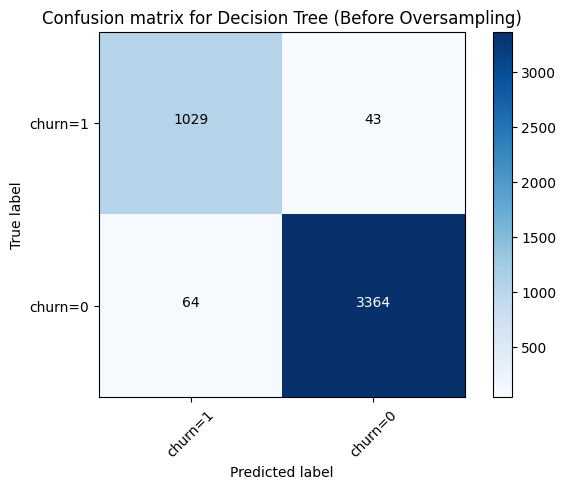

In [ ]:
plt.figure()
plot_confusion_matrix(cnf_matrix_dt, classes=['churn=1','churn=0'],
                      normalize= False,
                      title='Confusion matrix for Decision Tree (Before Oversampling)')

In [ ]:
cnf_matrix_dt_smote = confusion_matrix(y_test, dt_smote_y_pred, labels=[1,0])
np.set_printoptions(precision=2)
print(cnf_matrix_dt_smote)

[[1028   44]
 [ 131 3297]]


Confusion matrix, without normalization
[[1028   44]
 [ 131 3297]]


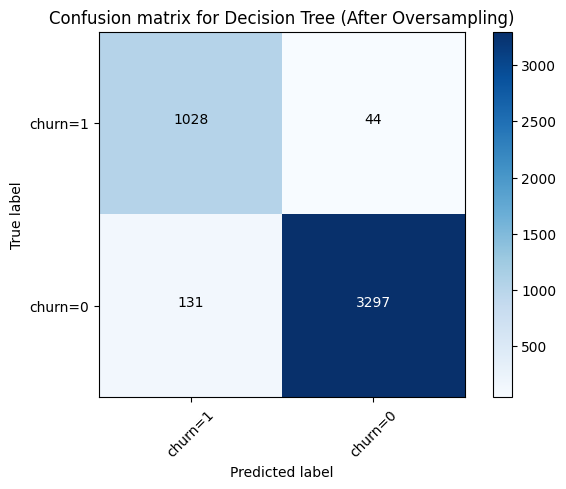

In [ ]:
plt.figure()
plot_confusion_matrix(cnf_matrix_dt_smote, classes=['churn=1','churn=0'],
                      normalize= False,
                      title='Confusion matrix for Decision Tree (After Oversampling)')

In [ ]:
print (classification_report(y_test, dt_y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3428
           1       0.94      0.96      0.95      1072

    accuracy                           0.98      4500
   macro avg       0.96      0.97      0.97      4500
weighted avg       0.98      0.98      0.98      4500



In [ ]:
print (classification_report(y_test, dt_smote_y_pred))

              precision    recall  f1-score   support

           0       0.99      0.96      0.97      3428
           1       0.89      0.96      0.92      1072

    accuracy                           0.96      4500
   macro avg       0.94      0.96      0.95      4500
weighted avg       0.96      0.96      0.96      4500



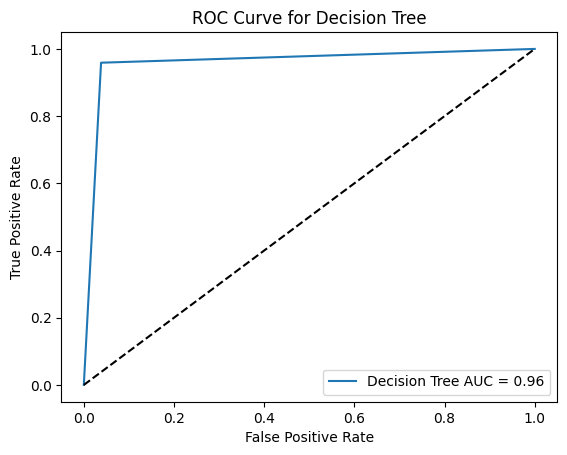

In [ ]:
!pip install scikit-learn  # Install scikit-learn if you haven't already

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Assuming you have 'y_test' (true labels) and your trained Decision Tree model 'dt' after applying SMOTE

# Get predicted probabilities from your Decision Tree model (dt)
y_pred_prob_dt = dt.predict_proba(X_test)[:, 1]  # Probability of class 1 (churn)

# Calculate the ROC curve
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_pred_prob_dt)

# Calculate the AUC
auc_dt = roc_auc_score(y_test, y_pred_prob_dt)

# Plot the ROC curve
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree AUC = {auc_dt:.2f}')
plt.plot([0, 1], [0, 1], 'k--')  # Dashed diagonal line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Decision Tree')
plt.legend(loc='lower right')
plt.show()